# Graph features for money laundering detection

## Problem
Money mules and laundering accounts rarely act alone: money moves **through chains of accounts**.
A model that only looks at each account's own behaviour can miss this.

## Approach
1. Build the **transfer network**: accounts are nodes, transfers are edges.
2. Compare three models on the same accounts:
   - **A. Account only**: each account's own behaviour (amounts, counts, payment types, pass-through).
   - **B. + Network structure**: number of counterparties, PageRank, ... (no labels used).
   - **C. + Closeness to known cases**: connections to accounts that were **already found** before.
3. **Time split**, close to real life: features use only transfers **before a cutoff T**.
   The target is accounts that are **not known yet** at T, and get involved in laundering **after T**.
   So the question is: *"Who should analysts look at next?"*
4. EBM to see **how** the network features change the risk.

## Data
[IBM Transactions for Anti Money Laundering (Kaggle)](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml):
synthetic bank transfers with a laundering label. Use `HI-Small_Trans.csv` (about 5M transfers).
Put it in `data/raw/ibm_aml/`, or set the environment variable `AML_DATA_PATH`.

If the file is not found, the notebook makes a **small fake file** so the code still runs (results are meaningless).

## 1. Setup

In [1]:
import os
import sys
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import train_test_split

sys.path.append("../src")
import graph_utils as gu

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)
COLORS = {"A. account only": "#8a8985", "B. + network structure": "#eb6834", "C. + closeness to known": "#2a78d6"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True, "axes.titleweight": "bold",
})

### Config
- `CUTOFF_QUANTILE`: the cutoff T is this quantile of transfer times. 0.6 = the first 60% of transfers are "the past".
- `TOP_K`: share of accounts analysts can review (0.01 = top 1%).

In [2]:
DATA_PATH = os.environ.get("AML_DATA_PATH", "../data/raw/ibm_aml/HI-Small_Trans.csv")
NROWS = None              # e.g. 1_000_000 to try quickly on part of the file
CUTOFF_QUANTILE = 0.6
TEST_SIZE = 0.3
TOP_K = 0.01
EBM_SAMPLE = 200_000      # rows used for the EBM (EBM is slower than LightGBM). None = all
RANDOM_STATE = 42

LGB_PARAMS = dict(
    n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1,
)

if not os.path.exists(DATA_PATH):
    print(f"{DATA_PATH} not found -> using a small synthetic file (results are NOT meaningful)")
    os.makedirs("../data/synthetic", exist_ok=True)
    DATA_PATH = gu.make_synthetic("../data/synthetic/synthetic_trans.csv")

## 2. Load transfers

In [3]:
t0 = time.time()
df = gu.load_transactions(DATA_PATH, nrows=NROWS)
print(f"{len(df):,} transfers   laundering: {df['is_laundering'].sum():,} ({df['is_laundering'].mean():.3%})   "
      f"load {time.time() - t0:.0f}s")
print("from", df["ts"].min(), "to", df["ts"].max())
print("currencies without a USD rate:", df.loc[df["amt_usd"].isna(), "cur_paid"].unique())

# transfers and laundering by day
daily = df.groupby(df["ts"].dt.date).agg(transfers=("is_laundering", "size"), laundering=("is_laundering", "sum"))
daily["laundering_rate"] = daily["laundering"] / daily["transfers"]
daily

5,078,345 transfers   laundering: 5,177 (0.102%)   load 13s
from 2022-09-01 00:00:00 to 2022-09-18 16:18:00
currencies without a USD rate: <ArrowStringArray>
[]
Length: 0, dtype: str


,transfers,laundering,laundering_rate
ts,,,
2022-09-01,1114921,322,0.0003
2022-09-02,754449,408,0.0005
2022-09-03,207382,391,0.0019
2022-09-04,207430,407,0.0020
2022-09-05,482650,471,0.0010
2022-09-06,482089,531,0.0011
2022-09-07,482751,497,0.0010
2022-09-08,482773,539,0.0011
2022-09-09,654467,514,0.0008


## 3. Time split
- **Known** = accounts involved in a laundering transfer before T (already found by investigators).
- **Target** = accounts not known at T that are involved in laundering after T.
- We score only accounts **active before T** and **not known yet**.

In [4]:
before, T, accounts, known, y_all = gu.time_split(df, CUTOFF_QUANTILE)
print(f"cutoff T: {T}")
print(f"transfers before T: {len(before):,}")
print(f"accounts active before T: {len(accounts):,}")
print(f"known before T: {known.sum():,}")
print(f"new laundering accounts after T (target): {y_all.sum():,}  ({y_all[~known].mean():.3%} of not-known accounts)")

cutoff T: 2022-09-06 13:36:00
transfers before T: 3,046,861
accounts active before T: 512,713
known before T: 3,170
new laundering accounts after T (target): 3,109  (0.610% of not-known accounts)


## 4. Features

In [5]:
t0 = time.time()
f_acct = gu.account_features(before, accounts)
C, A = gu.build_graph(before, accounts)
f_struct = gu.structure_features(C, accounts)
f_known = gu.known_neighbor_features(C, A, accounts, known)
print(f"graph: {C.shape[0]:,} accounts, {C.nnz:,} account pairs   features {time.time() - t0:.0f}s")

ACCT_COLS = list(f_acct.columns)
STRUCT_COLS = list(f_struct.columns)
KNOWN_COLS = list(f_known.columns)
FEATURE_SETS = {
    "A. account only": ACCT_COLS,
    "B. + network structure": ACCT_COLS + STRUCT_COLS,
    "C. + closeness to known": ACCT_COLS + STRUCT_COLS + KNOWN_COLS,
}

data = pd.concat([f_acct, f_struct, f_known], axis=1)
data["y"] = y_all
data = data[~known]                      # known accounts are not scored: they are already found
print(f"accounts to score: {len(data):,}   positives: {data['y'].sum():,}")
data[STRUCT_COLS + KNOWN_COLS].describe().T

graph: 512,713 accounts, 569,229 account pairs   features 14s
accounts to score: 509,543   positives: 3,109


,count,mean,std,min,25%,50%,75%,max
fan_out,509543.0000,1.0317,1.6442,0.0000,0.0000,1.0000,1.0000,32.0000
fan_in,509543.0000,1.0955,1.8269,0.0000,0.0000,1.0000,2.0000,93.0000
n_counterparties,509543.0000,2.1227,2.5515,0.0000,1.0000,1.0000,3.0000,93.0000
avg_counterparty_degree,509543.0000,256.2315,1299.9385,0.0000,1.0000,3.5000,6.0000,14775.0000
pagerank,509543.0000,0.9908,1.6561,0.5490,0.5490,0.6252,1.0559,158.0642
n_known_counterparties,509543.0000,0.0969,0.3029,0.0000,0.0000,0.0000,0.0000,3.0000
share_known_counterparties,509543.0000,0.0395,0.1468,0.0000,0.0000,0.0000,0.0000,1.0000
n_counterparties_near_known,509543.0000,0.3434,0.6659,0.0000,0.0000,0.0000,1.0000,54.0000
usd_from_known,509543.0000,188105.9393,8707525.8042,0.0000,0.0000,0.0000,0.0000,2033501825.2300
usd_to_known,509543.0000,9055.0849,1576957.9991,0.0000,0.0000,0.0000,0.0000,764301564.7280


**How do new laundering accounts differ?** Average of a few features, positives vs others.

In [6]:
show = ["n_sent", "n_recv", "pass_through", "fan_in", "fan_out", "pagerank",
        "n_known_counterparties", "n_counterparties_near_known", "hops_to_known"]
data.groupby("y")[show].mean().T.rename(columns={0: "others", 1: "new laundering"})

y,others,new laundering
n_sent,5.4090,9.9444
n_recv,5.9003,8.2708
pass_through,0.4366,0.4452
fan_in,1.0933,1.4423
fan_out,1.0294,1.4098
pagerank,0.9907,1.0144
n_known_counterparties,0.0963,0.2062
n_counterparties_near_known,0.3422,0.5445
hops_to_known,4.2674,3.4223


# Features

All features use only transfers **before the cutoff T**.
Amounts are converted to **US dollars**.

## A. Account only (19 features)

Each account's own behaviour. No network, no labels.

| Feature | What it means | Why it may matter |
|---|---|---|
| `n_sent` | Number of transfers the account sent | Very active accounts can be used to move money |
| `sum_sent_usd` | Total amount sent | Large amounts going out |
| `max_sent_usd` | Largest single transfer sent | One unusually large transfer |
| `median_sent_usd` | Typical size of a sent transfer | Laundering often uses similar, round amounts |
| `n_recv` | Number of transfers the account received | Many incoming transfers can mean collecting money |
| `sum_recv_usd` | Total amount received | Large amounts coming in |
| `max_recv_usd` | Largest single transfer received | One unusually large transfer |
| `median_recv_usd` | Typical size of a received transfer | Same as above, for incoming money |
| `pass_through` | How close money in and money out are (0 to 1). 1 = the same amount goes in and out | Mules receive money and send it on quickly |
| `share_sent_ach` | Share of sent transfers paid by ACH (bank transfer) | Some payment types are used more for laundering |
| `share_sent_bitcoin` | Share paid in Bitcoin | Harder to trace |
| `share_sent_cash` | Share paid in cash | Harder to trace |
| `share_sent_cheque` | Share paid by cheque | Payment type pattern |
| `share_sent_credit_card` | Share paid by credit card | Payment type pattern |
| `share_sent_reinvestment` | Share that is reinvestment (often to the same account) | Normal savings behaviour |
| `share_sent_wire` | Share paid by wire transfer | Fast, often cross-border |
| `n_currencies_sent` | Number of different currencies the account paid in | Using many currencies can hide the trail |
| `share_cross_currency` | Share of sent transfers where the paid and received currencies differ | Currency exchange is a common laundering step |
| `active_days` | Number of days with at least one transfer | Short bursts of activity can be suspicious |

## B. Network structure (5 features)

The account's position in the transfer network. No labels used.

| Feature | What it means | Why it may matter |
|---|---|---|
| `fan_out` | Number of different accounts it sent money to | Spreading money to many accounts |
| `fan_in` | Number of different accounts it received money from | Collecting money from many accounts |
| `n_counterparties` | Number of different accounts it is connected to, in either direction | Size of its network |
| `avg_counterparty_degree` | Average number of connections of its counterparties | Connected to hubs, or to small isolated accounts |
| `pagerank` | How central the account is: high when it receives from accounts that also receive a lot. 1 = average | Money tends to flow into central accounts |

## C. Closeness to known cases (6 features)

"Known" = accounts already involved in laundering before T (already found).

| Feature | What it means | Why it may matter |
|---|---|---|
| `n_known_counterparties` | Number of direct counterparties that are known cases | Mules often work with other mules |
| `share_known_counterparties` | Share of its counterparties that are known cases | Same, adjusted for network size |
| `n_counterparties_near_known` | Number of counterparties that are connected to a known case (two steps away) | Being close to a laundering group |
| `usd_from_known` | Total amount received from known cases | Money coming from a known laundering account |
| `usd_to_known` | Total amount sent to known cases | Money going to a known laundering account |
| `hops_to_known` | Steps to the nearest known case. 1 = direct counterparty, 7 = not connected within 6 steps | The closer, the higher the risk |

## How they are built (in one line each)

- **A**: group the transfers by sender or receiver, then count, sum and take shares.
- **B**: build a table of "who sent money to whom", then count rows and columns, and run PageRank.
- **C**: multiply that table by a list of known cases (1 = known, 0 = not). One multiplication = one step away, two = two steps away. `hops_to_known` uses a breadth-first search from all known cases.

## 5. Models: does the network help?

In [7]:
train, test = train_test_split(data, test_size=TEST_SIZE, stratify=data["y"], random_state=RANDOM_STATE)
y_tr, y_te = train["y"].to_numpy(), test["y"].to_numpy()

scores, models, rows = {}, {}, []
t0 = time.time()
for name, cols in FEATURE_SETS.items():
    m = lgb.LGBMClassifier(**LGB_PARAMS).fit(train[cols], y_tr)
    p = m.predict_proba(test[cols])[:, 1]
    scores[name], models[name] = p, m
    rows.append({"model": name, "features": len(cols),
                 "AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p),
                 f"recall @ top {TOP_K:.0%}": gu.recall_at_k(y_te, p, TOP_K),
                 f"precision @ top {TOP_K:.0%}": gu.precision_at_k(y_te, p, TOP_K)})
print(f"3 models: {time.time() - t0:.0f}s   test positives: {y_te.sum():,} of {len(y_te):,}")
results = pd.DataFrame(rows).set_index("model")
results

3 models: 11s   test positives: 933 of 152,863


,features,AUC,PR-AUC,recall @ top 1%,precision @ top 1%
model,,,,,
A. account only,19,0.6873,0.0116,0.0332,0.0203
B. + network structure,24,0.6987,0.0126,0.0364,0.0222
C. + closeness to known,30,0.7059,0.0138,0.0439,0.0268


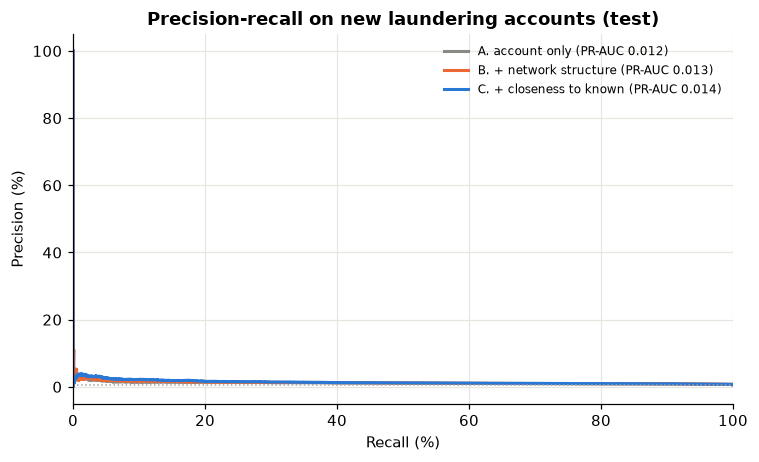

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.3))
for name, p in scores.items():
    prec, rec, _ = precision_recall_curve(y_te, p)
    ax.plot(rec * 100, prec * 100, color=COLORS[name], lw=2, label=f"{name} (PR-AUC {average_precision_score(y_te, p):.3f})")
ax.axhline(y_te.mean() * 100, color="#a3a3a3", ls=":", lw=1)
ax.set(title="Precision-recall on new laundering accounts (test)", xlabel="Recall (%)", ylabel="Precision (%)", xlim=(0, 100))
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 6. Business view
Analysts can review the top 1% of accounts. How many **new** laundering accounts does each model put in front of them?

In [9]:
n_review = max(1, int(round(len(y_te) * TOP_K)))
pd.DataFrame({
    name: {"reviewed": n_review,
           "laundering accounts found": int(y_te[np.argsort(-p)[:n_review]].sum()),
           "all laundering accounts in test": int(y_te.sum())}
    for name, p in scores.items()
}).T

,reviewed,laundering accounts found,all laundering accounts in test
A. account only,1529,31,933
B. + network structure,1529,34,933
C. + closeness to known,1529,41,933


## 7. Which features matter? (LightGBM, model C)
Gain importance: how much each feature improves the trees. Network features are marked.

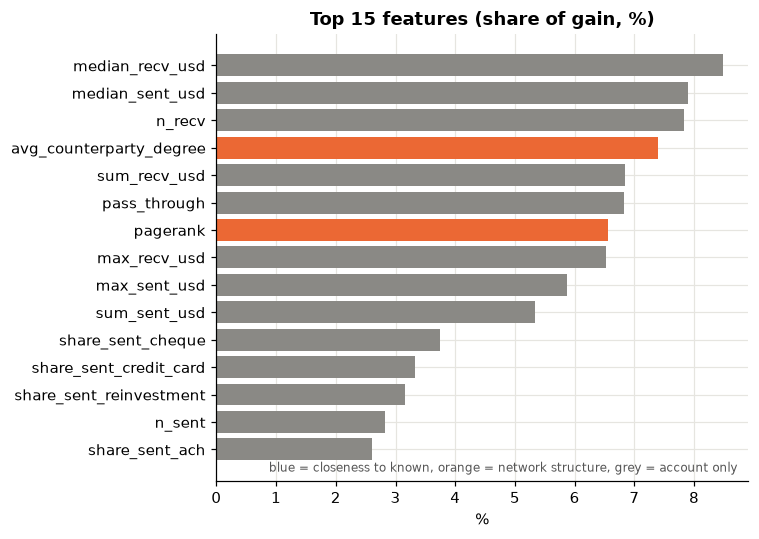

In [10]:
m = models["C. + closeness to known"]
imp = pd.Series(m.booster_.feature_importance("gain"), index=FEATURE_SETS["C. + closeness to known"])
imp = (imp / imp.sum()).sort_values().tail(15)
colors = ["#2a78d6" if c in KNOWN_COLS else "#eb6834" if c in STRUCT_COLS else "#8a8985" for c in imp.index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values * 100, color=colors)
ax.set(title="Top 15 features (share of gain, %)", xlabel="%")
ax.text(0.98, 0.02, "blue = closeness to known, orange = network structure, grey = account only",
        transform=ax.transAxes, ha="right", fontsize=8, color="#555")
plt.tight_layout(); plt.show()

## 8. EBM: how the network features change the risk
Same features as model C, as an EBM (no interactions, so each feature has one shape).

In [11]:
cols = FEATURE_SETS["C. + closeness to known"]
tr = train
if EBM_SAMPLE is not None and len(train) > EBM_SAMPLE:
    pos = train[train["y"] == 1]
    neg = train[train["y"] == 0].sample(EBM_SAMPLE - len(pos), random_state=RANDOM_STATE)
    tr = pd.concat([pos, neg])
    print(f"EBM on {len(tr):,} rows (all {len(pos):,} positives + sampled negatives)")

t0 = time.time()
ebm = ExplainableBoostingClassifier(interactions=0, random_state=RANDOM_STATE, n_jobs=-1).fit(tr[cols], tr["y"])
p_ebm = ebm.predict_proba(test[cols])[:, 1]
print(f"EBM {time.time() - t0:.0f}s   AUC {roc_auc_score(y_te, p_ebm):.4f}   PR-AUC {average_precision_score(y_te, p_ebm):.4f}"
      f"   recall @ top {TOP_K:.0%}: {gu.recall_at_k(y_te, p_ebm, TOP_K):.3f}")

EBM on 200,000 rows (all 2,176 positives + sampled negatives)
EBM 37s   AUC 0.7027   PR-AUC 0.0150   recall @ top 1%: 0.048


max_recv_usd             0.3239
share_sent_credit_card   0.2626
n_recv                   0.2201
fan_in                   0.1141
sum_sent_usd             0.1030
median_recv_usd          0.0961
max_sent_usd             0.0813
hops_to_known            0.0810
pagerank                 0.0801
active_days              0.0593


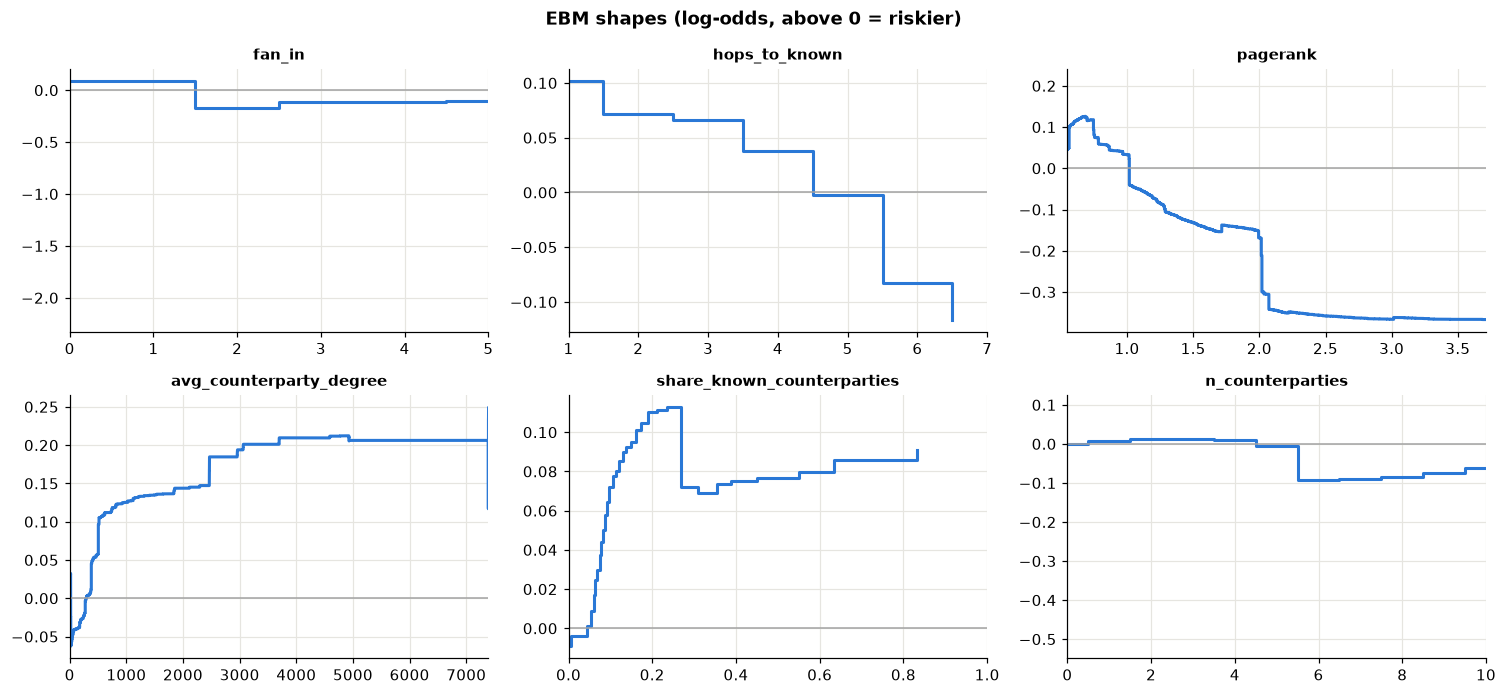

In [12]:
def plot_ebm_shapes(ebm, features, X_ref, ncols=3, clip=(0.01, 0.99)):
    names = list(ebm.term_names_)
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.2 * nrows), squeeze=False)
    axes = axes.ravel()
    for ax in axes[len(features):]:
        ax.set_visible(False)
    for f, ax in zip(features, axes):
        d = ebm.explain_global().data(names.index(f))
        x = np.asarray(d["names"], dtype=float)[:-1]
        sc = np.asarray(d["scores"], dtype=float)
        ax.step(x, sc, where="post", color="#2a78d6", lw=2)
        lo, hi = np.nanpercentile(X_ref[f].astype(float), [clip[0] * 100, clip[1] * 100])
        if hi > lo:
            ax.set_xlim(lo, hi)
        ax.axhline(0, color="#a3a3a3", lw=1)
        ax.set_title(f, fontsize=10)
    fig.suptitle("EBM shapes (log-odds, above 0 = riskier)", fontweight="bold")
    plt.tight_layout(); plt.show()

imp_ebm = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values(ascending=False)
print(imp_ebm.head(10).round(4).to_string())
network_top = [c for c in imp_ebm.index if c in STRUCT_COLS + KNOWN_COLS][:6]
plot_ebm_shapes(ebm, network_top, tr)

**How to read**
- `hops_to_known`: 1 = direct counterparty of a known case, 2 = two steps away, 7 = not connected within 6 steps.
  If the risk is high at 1–2 and drops after, being close to known cases matters.
- `pass_through`: close to 1 = money in ≈ money out (typical for mules).
- `fan_in` / `fan_out`: many different counterparties can mean collecting or spreading money.

## 9. One account in the network
A new laundering account from the test set that the model ranked high, with its direct counterparties
and theirs (2 steps). Known accounts (found before T) are red.

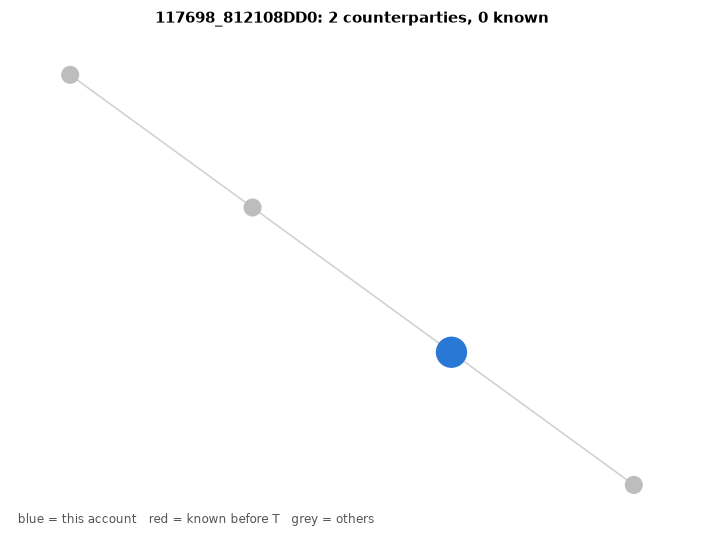

In [13]:
def plot_neighborhood(acct_id, C, accounts, known, max_nodes=60, seed=RANDOM_STATE):
    U = gu.undirected(C)
    i = accounts.get_loc(acct_id)
    hop1 = U[i].indices
    hop2 = np.setdiff1d(np.unique(U[hop1].indices), np.r_[hop1, i]) if len(hop1) else np.array([], int)
    rng = np.random.default_rng(seed)
    keep2 = hop2[known[hop2]]                                  # always show known accounts at 2 steps
    rest = np.setdiff1d(hop2, keep2)
    room = max(0, max_nodes - 1 - len(hop1) - len(keep2))
    nodes = np.r_[i, hop1, keep2, rng.choice(rest, size=min(room, len(rest)), replace=False)].astype(int)
    G = nx.Graph()
    sub = U[nodes][:, nodes].tocoo()
    G.add_nodes_from(range(len(nodes)))
    G.add_edges_from(zip(sub.row, sub.col))
    pos = nx.spring_layout(G, seed=seed)
    col = ["#d64541" if known[n] else "#bdbdbd" for n in nodes]
    col[0] = "#2a78d6"
    size = [420] + [140] * (len(nodes) - 1)
    fig, ax = plt.subplots(figsize=(6.5, 5))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#cfcfcf", width=1)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=col, node_size=size, linewidths=0)
    ax.set_title(f"{acct_id}: {len(hop1)} counterparties, {int(known[hop1].sum())} known", fontsize=10)
    ax.text(0.01, 0.01, "blue = this account   red = known before T   grey = others", transform=ax.transAxes,
            fontsize=8, color="#555")
    ax.axis("off"); plt.tight_layout(); plt.show()

p_c = scores["C. + closeness to known"]
cand = test.assign(score=p_c)
cand = cand[(cand["y"] == 1) & (cand["n_counterparties"].between(2, 40))].sort_values("score", ascending=False)
if len(cand):
    plot_neighborhood(cand.index[0], C, accounts, known)
else:
    print("no suitable account to show")

## 10. Notes
Write your own observations after running:
- How much did network structure (B) and closeness to known cases (C) add over account-only features (A)?
- How many more new laundering accounts are in the top 1%?
- Which network features matter most, and what do their EBM shapes say?

**Limitations**
- The data is **synthetic** (IBM's simulator). Real networks are messier, and links between banks are only partly visible to one bank.
- Only accounts **active before T** are scored. Brand-new accounts need other signals.
- "Known" cases are only the ones that were **found**. Some laundering accounts are never found (the PU problem):
  unlabeled accounts close to known cases are good candidates for review, and for higher PU weights.

from sklearn.model_selection import StratifiedKFold
 
LABEL_FREQ = 0.5      # share of laundering accounts that keep their label in training (true c)
N_FOLDS = 5
 
rng = np.random.default_rng(RANDOM_STATE)
y_tr, y_te = train["y"].to_numpy(), test["y"].to_numpy()
s_tr = ((y_tr == 1) & (rng.uniform(size=len(y_tr)) < LABEL_FREQ)).astype(int)
hidden = (y_tr == 1) & (s_tr == 0)
c_true = s_tr[y_tr == 1].mean()
print(f"training: {y_tr.sum():,} laundering accounts, {s_tr.sum():,} labeled, {hidden.sum():,} hidden   true c = {c_true:.3f}")
 
 
def pu_weights(g, c, eps=1e-6):
    # chance that an unlabeled account is hidden laundering
    g = np.clip(g, eps, 1 - eps)
    return np.clip((1 - c) / c * g / (1 - g), 0, 1)
 
 
def cross_fit_g(X, s):
    # step 1: g(x) = P(labeled | x), each row scored by a model that did not see it
    g = np.zeros(len(s))
    for tr_idx, va_idx in StratifiedKFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X, s):
        m = lgb.LGBMClassifier(**LGB_PARAMS).fit(X.iloc[tr_idx], s[tr_idx])
        g[va_idx] = m.predict_proba(X.iloc[va_idx])[:, 1]
    return g
 
 
def fit_pu(X, s, w):
    # final model: labeled = laundering (weight 1); unlabeled used twice (laundering w, normal 1 - w)
    pos, unl = s == 1, s == 0
    X_new = pd.concat([X[pos], X[unl], X[unl]], ignore_index=True)
    y_new = np.r_[np.ones(pos.sum()), np.zeros(unl.sum()), np.ones(unl.sum())]
    w_new = np.r_[np.ones(pos.sum()), 1 - w[unl], w[unl]]
    keep = w_new > 0
    return lgb.LGBMClassifier(**LGB_PARAMS).fit(X_new[keep], y_new[keep], sample_weight=w_new[keep])
 
 
def evaluate(y, p):
    return {"AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            f"recall @ top {TOP_K:.0%}": gu.recall_at_k(y, p, TOP_K), "mean score": p.mean()}
 
 
PU_SETS = ["A. account only", "C. + closeness to known"]
rows, weights, gs = [], {}, {}
t0 = time.time()
for fs in PU_SETS:
    cols = FEATURE_SETS[fs]
    X_tr, X_te = train[cols], test[cols]
    p_oracle = lgb.LGBMClassifier(**LGB_PARAMS).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    p_naive = lgb.LGBMClassifier(**LGB_PARAMS).fit(X_tr, s_tr).predict_proba(X_te)[:, 1]
    g = cross_fit_g(X_tr, s_tr)
    w = np.where(s_tr == 0, pu_weights(g, c_true), 0.0)
    p_pu = fit_pu(X_tr, s_tr, w).predict_proba(X_te)[:, 1]
    gs[fs], weights[fs] = g, w
    print(f"{fs}: c from the data {g[s_tr == 1].mean():.3f} (true {c_true:.3f})   "
          f"mean w  hidden {w[hidden].mean():.3f} vs true normal {w[y_tr == 0].mean():.4f}")
    for name, p in [("oracle", p_oracle), ("naive", p_naive), ("PU", p_pu)]:
        rows.append({"features": fs, "model": name, **evaluate(y_te, p)})
print(f"{time.time() - t0:.0f}s   true rate in test: {y_te.mean():.4f}")
pu_results = pd.DataFrame(rows).set_index(["features", "model"])
pu_results
 
# %% [markdown]
# **Share of the naive → oracle gap closed by PU** (100% = as good as the true labels).
 
# %%
gap = {}
for fs in PU_SETS:
    r = pu_results.loc[fs]
    gap[fs] = {}
    for col in ["AUC", "PR-AUC", f"recall @ top {TOP_K:.0%}"]:
        d = r.loc["oracle", col] - r.loc["naive", col]
        gap[fs][col] = (r.loc["PU", col] - r.loc["naive", col]) / d if abs(d) > 1e-9 else np.nan
pd.DataFrame(gap).T.style.format("{:.0%}")

In [15]:
from sklearn.model_selection import StratifiedKFold
 
LABEL_FREQ = 0.5      # share of laundering accounts that keep their label in training (true c)
N_FOLDS = 5
 
rng = np.random.default_rng(RANDOM_STATE)
y_tr, y_te = train["y"].to_numpy(), test["y"].to_numpy()
s_tr = ((y_tr == 1) & (rng.uniform(size=len(y_tr)) < LABEL_FREQ)).astype(int)
hidden = (y_tr == 1) & (s_tr == 0)
c_true = s_tr[y_tr == 1].mean()
print(f"training: {y_tr.sum():,} laundering accounts, {s_tr.sum():,} labeled, {hidden.sum():,} hidden   true c = {c_true:.3f}")
 
 
def pu_weights(g, c, eps=1e-6):
    # chance that an unlabeled account is hidden laundering
    g = np.clip(g, eps, 1 - eps)
    return np.clip((1 - c) / c * g / (1 - g), 0, 1)
 
 
def cross_fit_g(X, s):
    # step 1: g(x) = P(labeled | x), each row scored by a model that did not see it
    g = np.zeros(len(s))
    for tr_idx, va_idx in StratifiedKFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X, s):
        m = lgb.LGBMClassifier(**LGB_PARAMS).fit(X.iloc[tr_idx], s[tr_idx])
        g[va_idx] = m.predict_proba(X.iloc[va_idx])[:, 1]
    return g
 
 
def fit_pu(X, s, w):
    # final model: labeled = laundering (weight 1); unlabeled used twice (laundering w, normal 1 - w)
    pos, unl = s == 1, s == 0
    X_new = pd.concat([X[pos], X[unl], X[unl]], ignore_index=True)
    y_new = np.r_[np.ones(pos.sum()), np.zeros(unl.sum()), np.ones(unl.sum())]
    w_new = np.r_[np.ones(pos.sum()), 1 - w[unl], w[unl]]
    keep = w_new > 0
    return lgb.LGBMClassifier(**LGB_PARAMS).fit(X_new[keep], y_new[keep], sample_weight=w_new[keep])
 
 
def evaluate(y, p):
    return {"AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            f"recall @ top {TOP_K:.0%}": gu.recall_at_k(y, p, TOP_K), "mean score": p.mean()}
 
 
PU_SETS = ["A. account only", "C. + closeness to known"]
rows, weights, gs = [], {}, {}
t0 = time.time()
for fs in PU_SETS:
    cols = FEATURE_SETS[fs]
    X_tr, X_te = train[cols], test[cols]
    p_oracle = lgb.LGBMClassifier(**LGB_PARAMS).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    p_naive = lgb.LGBMClassifier(**LGB_PARAMS).fit(X_tr, s_tr).predict_proba(X_te)[:, 1]
    g = cross_fit_g(X_tr, s_tr)
    w = np.where(s_tr == 0, pu_weights(g, c_true), 0.0)
    p_pu = fit_pu(X_tr, s_tr, w).predict_proba(X_te)[:, 1]
    gs[fs], weights[fs] = g, w
    print(f"{fs}: c from the data {g[s_tr == 1].mean():.3f} (true {c_true:.3f})   "
          f"mean w  hidden {w[hidden].mean():.3f} vs true normal {w[y_tr == 0].mean():.4f}")
    for name, p in [("oracle", p_oracle), ("naive", p_naive), ("PU", p_pu)]:
        rows.append({"features": fs, "model": name, **evaluate(y_te, p)})
print(f"{time.time() - t0:.0f}s   true rate in test: {y_te.mean():.4f}")
pu_results = pd.DataFrame(rows).set_index(["features", "model"])
pu_results
 
# %% [markdown]
# **Share of the naive → oracle gap closed by PU** (100% = as good as the true labels).
 
# %%
gap = {}
for fs in PU_SETS:
    r = pu_results.loc[fs]
    gap[fs] = {}
    for col in ["AUC", "PR-AUC", f"recall @ top {TOP_K:.0%}"]:
        d = r.loc["oracle", col] - r.loc["naive", col]
        gap[fs][col] = (r.loc["PU", col] - r.loc["naive", col]) / d if abs(d) > 1e-9 else np.nan
pd.DataFrame(gap).T.style.format("{:.0%}")

training: 2,176 laundering accounts, 1,068 labeled, 1,108 hidden   true c = 0.491
A. account only: c from the data 0.004 (true 0.491)   mean w  hidden 0.004 vs true normal 0.0024
C. + closeness to known: c from the data 0.005 (true 0.491)   mean w  hidden 0.004 vs true normal 0.0023
63s   true rate in test: 0.0061


,AUC,PR-AUC,recall @ top 1%
A. account only,48%,35%,17%
C. + closeness to known,40%,10%,38%


In [17]:
gap = {}
for fs in PU_SETS:
    r = pu_results.loc[fs]
    gap[fs] = {}
    for col in ["AUC", "PR-AUC", f"recall @ top {TOP_K:.0%}"]:
        d = r.loc["oracle", col] - r.loc["naive", col]
        gap[fs][col] = (r.loc["PU", col] - r.loc["naive", col]) / d if abs(d) > 1e-9 else np.nan
pd.DataFrame(gap).T.style.format("{:.0%}")

,AUC,PR-AUC,recall @ top 1%
A. account only,48%,35%,17%
C. + closeness to known,40%,10%,38%


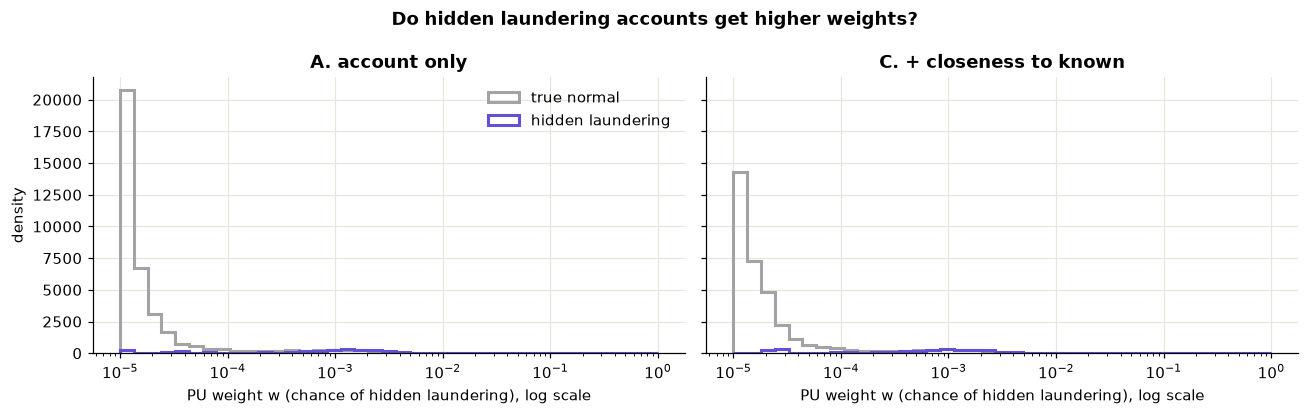

In [19]:
unl = s_tr == 0
n_top = max(1, int(round(unl.sum() * TOP_K)))
rows = []
for fs in PU_SETS:
    top = np.argsort(-weights[fs][unl])[:n_top]
    found = hidden[unl][top].sum()
    rows.append({"features": fs, "unlabeled checked": n_top, "hidden found": int(found),
                 "share of hidden found": found / max(1, hidden.sum())})
pd.DataFrame(rows).set_index("features")
 
# %%
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
bins = np.logspace(-5, 0, 40)
for fs, ax in zip(PU_SETS, axes):
    w = weights[fs]
    for mask, col, lab in [(y_tr == 0, "#a3a3a3", "true normal"), (hidden, "#6250d6", "hidden laundering")]:
        ax.hist(np.clip(w[mask], 1e-5, 1), bins=bins, density=True, histtype="step", lw=2, color=col, label=lab)
    ax.set_xscale("log")
    ax.set(title=fs, xlabel="PU weight w (chance of hidden laundering), log scale")
axes[0].set_ylabel("density"); axes[0].legend(frameon=False)
fig.suptitle("Do hidden laundering accounts get higher weights?", fontweight="bold")
plt.tight_layout(); plt.show()